# Unsupervised Color-Based Clustering of TV Show Posters with IMDb Metadata Analysis

In [1]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')

In [2]:
def get_random_images(filepath, n=1000):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [3]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [4]:
def get_imdb_data(imdb_id, imdbCSV):
    """Get IMDB data from the specified CSV file."""
    try:
        tmpDF = pd.read_csv(imdbCSV)
        row = tmpDF[tmpDF['imdb_id'] == imdb_id]
        
        # Include genres in the returned data
        genres = [genre.strip() for genre in row['genres'].iloc[0].split(',')]
        
        show_data = {
            'imdb_id': imdb_id,
            'title': row['title'].iloc[0],
            'rating': row['rating'].iloc[0],
            'rating_count': row['rating_count'].iloc[0],
            'content_rating': row['content_rating'].iloc[0] if 'content_rating' in row.columns else '',
            'date_published': row['date_published'].iloc[0],
            'genres': genres
        }
        return show_data
    except Exception as e:
        return None

In [5]:
def extract_color_features(image_path):
    """Extract color histogram features from image."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Resize for consistency
    img_resized = cv2.resize(img, (224, 336))
    
    # Convert to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Calculate RGBW values 
    features = {}
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  # White component as average of RGB
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

In [6]:
def create_dataset(image_folder, imdbCSV):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder)
    data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id, imdbCSV)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            color_features = extract_color_features(img_path)

            if color_features is not None:
                tempyear = show_data['date_published'][:4]
                genres = show_data['genres']
                
                combined_data = {
                    'imdb_id': imdb_id,
                    'r_mean': color_features[0],
                    'g_mean': color_features[1],
                    'b_mean': color_features[2],
                    'w_mean': color_features[3],
                    'rating': show_data['rating'],
                    'year': int(tempyear),
                    'genres': genres
                }
                data.append(combined_data)
    
    df = pd.DataFrame(data)
    
    # Create one-hot encoding for genres
    all_genres = []
    for genres in df['genres']:
        all_genres.extend(genres)
    unique_genres = sorted(list(set(all_genres)))
    
    # Create genre columns
    for genre in unique_genres:
        df[f'genre_{genre}'] = df['genres'].apply(lambda x: 1 if genre in x else 0)
    
    # Drop the original genres column
    df = df.drop('genres', axis=1)
    
    return df

In [7]:
def perform_pca_analysis(df):
    """Perform PCA on non-genre features."""
    # Separate genre and non-genre features
    genre_columns = [col for col in df.columns if col.startswith('genre_')]
    non_genre_columns = [col for col in df.columns if not col.startswith('genre_') and col != 'imdb_id']
    
    # Prepare feature matrix for non-genre features
    X = df[non_genre_columns]
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Find number of components needed for 80% variance
    n_components = np.argmax(cum_var_ratio >= 0.8) + 1
    
    # Combine PCA components with genre features
    pca_df = pd.DataFrame(X_pca[:, :n_components], columns=[f'PC{i+1}' for i in range(n_components)])
    genre_df = df[genre_columns]
    
    # Combine PCA components with genre features
    combined_features = pd.concat([pca_df, genre_df], axis=1)
    
    return pca, combined_features, n_components, X.columns

In [8]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

In [9]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [10]:
def plot_pca_features(pca, X_pca, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    df_pca = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
    
    plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.7, edgecolors='k')
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [11]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [12]:
def plot_clustering_comparison(combined_features, n_components):
    """Plot different clustering methods with genre visualization."""
    from sklearn.cluster import KMeans, DBSCAN, Birch
    from sklearn.mixture import GaussianMixture
    from scipy.cluster.hierarchy import linkage, fcluster
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    # Separate PCA and genre features
    pca_cols = [f'PC{i+1}' for i in range(n_components)]
    genre_cols = [col for col in combined_features.columns if col.startswith('genre_')]
    
    X_pca = combined_features[pca_cols]
    X_genres = combined_features[genre_cols]
    
    # Calculate genre density for point size
    genre_density = X_genres.sum(axis=1)
    size_scale = 50 * (genre_density - genre_density.min()) / (genre_density.max() - genre_density.min()) + 20
    
    # Create figure with two rows
    fig = plt.figure(figsize=(25, 20))
    
    # First row: Scatter plots
    # K-means
    ax1 = fig.add_subplot(251)
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(combined_features)
    scatter1 = ax1.scatter(X_pca.iloc[:, 0], X_pca.iloc[:, 1], 
                          c=kmeans_labels, cmap='viridis',
                          s=size_scale)
    ax1.set_title('K-means Clustering\n(point size = genre count)')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Hierarchical
    ax2 = fig.add_subplot(252)
    Z = linkage(combined_features, method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca.iloc[:, 0], X_pca.iloc[:, 1], 
                          c=hier_labels, cmap='viridis',
                          s=size_scale)
    ax2.set_title('Hierarchical Clustering\n(point size = genre count)')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    
    # DBSCAN
    ax3 = fig.add_subplot(253)
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(combined_features)
    scatter3 = ax3.scatter(X_pca.iloc[:, 0], X_pca.iloc[:, 1], 
                          c=dbscan_labels, cmap='viridis',
                          s=size_scale)
    ax3.set_title('DBSCAN Clustering\n(point size = genre count)')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    
    # GMM
    ax4 = fig.add_subplot(254)
    gmm = GaussianMixture(n_components=3, random_state=42)
    gmm_labels = gmm.fit_predict(combined_features)
    scatter4 = ax4.scatter(X_pca.iloc[:, 0], X_pca.iloc[:, 1], 
                          c=gmm_labels, cmap='viridis',
                          s=size_scale)
    ax4.set_title('Gaussian Mixture Model\n(point size = genre count)')
    ax4.set_xlabel('PC1')
    ax4.set_ylabel('PC2')
    
    # BIRCH
    ax5 = fig.add_subplot(255)
    birch = Birch(n_clusters=3)
    birch_labels = birch.fit_predict(combined_features)
    scatter5 = ax5.scatter(X_pca.iloc[:, 0], X_pca.iloc[:, 1], 
                          c=birch_labels, cmap='viridis',
                          s=size_scale)
    ax5.set_title('BIRCH Clustering\n(point size = genre count)')
    ax5.set_xlabel('PC1')
    ax5.set_ylabel('PC2')
    
    # Second row: Genre heatmaps
    # K-means genres
    ax6 = fig.add_subplot(256)
    kmeans_genre_dist = pd.DataFrame()
    for cluster in np.unique(kmeans_labels):
        kmeans_genre_dist[f'Cluster {cluster}'] = X_genres[kmeans_labels == cluster].mean()
    sns.heatmap(kmeans_genre_dist, ax=ax6, cmap='YlOrRd')
    ax6.set_title('Genre Distribution in K-means Clusters')
    ax6.set_xticklabels(ax6.get_xticklabels(), rotation=45)
    
    # Hierarchical genres
    ax7 = fig.add_subplot(257)
    hier_genre_dist = pd.DataFrame()
    for cluster in np.unique(hier_labels):
        hier_genre_dist[f'Cluster {cluster}'] = X_genres[hier_labels == cluster].mean()
    sns.heatmap(hier_genre_dist, ax=ax7, cmap='YlOrRd')
    ax7.set_title('Genre Distribution in Hierarchical Clusters')
    ax7.set_xticklabels(ax7.get_xticklabels(), rotation=45)
    
    # DBSCAN genres
    ax8 = fig.add_subplot(258)
    dbscan_genre_dist = pd.DataFrame()
    for cluster in np.unique(dbscan_labels):
        dbscan_genre_dist[f'Cluster {cluster}'] = X_genres[dbscan_labels == cluster].mean()
    sns.heatmap(dbscan_genre_dist, ax=ax8, cmap='YlOrRd')
    ax8.set_title('Genre Distribution in DBSCAN Clusters')
    ax8.set_xticklabels(ax8.get_xticklabels(), rotation=45)
    
    # GMM genres
    ax9 = fig.add_subplot(259)
    gmm_genre_dist = pd.DataFrame()
    for cluster in np.unique(gmm_labels):
        gmm_genre_dist[f'Cluster {cluster}'] = X_genres[gmm_labels == cluster].mean()
    sns.heatmap(gmm_genre_dist, ax=ax9, cmap='YlOrRd')
    ax9.set_title('Genre Distribution in GMM Clusters')
    ax9.set_xticklabels(ax9.get_xticklabels(), rotation=45)
    
    # BIRCH genres
    ax10 = fig.add_subplot(2,5,10)
    birch_genre_dist = pd.DataFrame()
    for cluster in np.unique(birch_labels):
        birch_genre_dist[f'Cluster {cluster}'] = X_genres[birch_labels == cluster].mean()
    sns.heatmap(birch_genre_dist, ax=ax10, cmap='YlOrRd')
    ax10.set_title('Genre Distribution in BIRCH Clusters')
    ax10.set_xticklabels(ax10.get_xticklabels(), rotation=45)
    
    # Add colorbars for cluster plots
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    fig.colorbar(scatter4, ax=ax4, label='Cluster')
    fig.colorbar(scatter5, ax=ax5, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [13]:
def analyze_clusters(combined_features, n_clusters_range=range(2, 7)):
    """
    Analyze clusters using Silhouette Score and Davies-Bouldin Index for different clustering methods.
    Returns results in tabular format.
    """
    from sklearn.metrics import silhouette_score, davies_bouldin_score
    from sklearn.cluster import KMeans, DBSCAN, Birch
    from sklearn.mixture import GaussianMixture
    from scipy.cluster.hierarchy import linkage, fcluster
    import pandas as pd
    import numpy as np
    
    # Initialize results storage
    results = []
    
    # K-means evaluation
    for n_clusters in n_clusters_range:
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(combined_features)
        
        results.append({
            'Method': 'K-means',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(combined_features, labels),
            'Davies-Bouldin Index': davies_bouldin_score(combined_features, labels)
        })
    
    # Hierarchical evaluation
    for n_clusters in n_clusters_range:
        Z = linkage(combined_features, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
        
        results.append({
            'Method': 'Hierarchical',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(combined_features, labels),
            'Davies-Bouldin Index': davies_bouldin_score(combined_features, labels)
        })
    
    # DBSCAN evaluation
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    labels = dbscan.fit_predict(combined_features)
    
    # Only calculate scores if DBSCAN found more than one cluster
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters > 1:
        results.append({
            'Method': 'DBSCAN',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(combined_features, labels),
            'Davies-Bouldin Index': davies_bouldin_score(combined_features, labels)
        })
    
    # GMM evaluation
    for n_clusters in n_clusters_range:
        gmm = GaussianMixture(n_components=n_clusters, random_state=42)
        labels = gmm.fit_predict(combined_features)
        
        results.append({
            'Method': 'GMM',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(combined_features, labels),
            'Davies-Bouldin Index': davies_bouldin_score(combined_features, labels)
        })
    
    # BIRCH evaluation
    for n_clusters in n_clusters_range:
        birch = Birch(n_clusters=n_clusters)
        labels = birch.fit_predict(combined_features)
        
        results.append({
            'Method': 'BIRCH',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(combined_features, labels),
            'Davies-Bouldin Index': davies_bouldin_score(combined_features, labels)
        })
    
    # Create DataFrame
    df_results = pd.DataFrame(results)
    
    # Format the metrics to 3 decimal places
    df_results['Silhouette Score'] = df_results['Silhouette Score'].round(3)
    df_results['Davies-Bouldin Index'] = df_results['Davies-Bouldin Index'].round(3)
    
    # Print formatted tables
    print("\nClustering Evaluation Results:")
    print(df_results.to_string(index=False))
    
    # Create summary of best results
    print("\nBest Results:")
    best_silhouette = df_results.loc[df_results['Silhouette Score'].idxmax()]
    best_davies = df_results.loc[df_results['Davies-Bouldin Index'].idxmin()]
    
    summary = pd.DataFrame([
        {
            'Metric': 'Best Silhouette Score',
            'Method': best_silhouette['Method'],
            'n_clusters': best_silhouette['n_clusters'],
            'Score': best_silhouette['Silhouette Score']
        },
        {
            'Metric': 'Best Davies-Bouldin Index',
            'Method': best_davies['Method'],
            'n_clusters': best_davies['n_clusters'],
            'Score': best_davies['Davies-Bouldin Index']
        }
    ])
    
    print(summary.to_string(index=False))
    
    return df_results

In [14]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "tv_show_posters"
imdbCSV = "tv_shows_data.csv"
combined_df = create_dataset(IMAGE_FOLDER, imdbCSV)   

Step 1: Gathering data...


In [15]:
print("\nIMDB Data Sample:")
combined_df.head()


IMDB Data Sample:


,imdb_id,r_mean,g_mean,b_mean,w_mean,rating,year,genre_Action,genre_Adventure,genre_Animation,...,genre_News,genre_Reality-TV,genre_Romance,genre_Sci-Fi,genre_Short,genre_Sport,genre_Talk-Show,genre_Thriller,genre_War,genre_Western
0,tt20835112,156.357767,194.215216,201.019305,48.298337,6.4,2022,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,tt11147864,245.837784,231.621825,232.002299,71.530386,6.9,2020,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,tt1062207,120.053332,103.017698,94.171078,34.938979,6.5,2007,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,tt15675716,117.696203,103.037800,91.091518,36.888552,8.9,2021,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,tt2520406,136.057039,127.510191,126.390811,45.762658,6.2,2008,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [16]:
# Perform PCA analysis
print("\nStep 2: Performing PCA analysis...")
pca, X_pca, n_components, feature_names = perform_pca_analysis(combined_df)


Step 2: Performing PCA analysis...


In [17]:
# Display PCA results
print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
print(evr)


Explained variance ratios:
                     Explained Variance Ratio
Principal Component                          
PC1                                  0.543345
PC2                                  0.186038
PC3                                  0.148304
PC4                                  0.059002
PC5                                  0.050032
PC6                                  0.013280


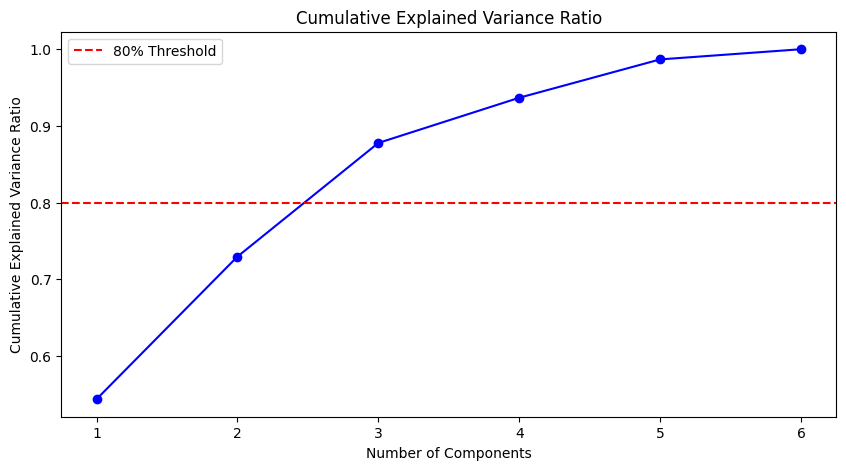

In [18]:
plot_cumulative_variance(pca)

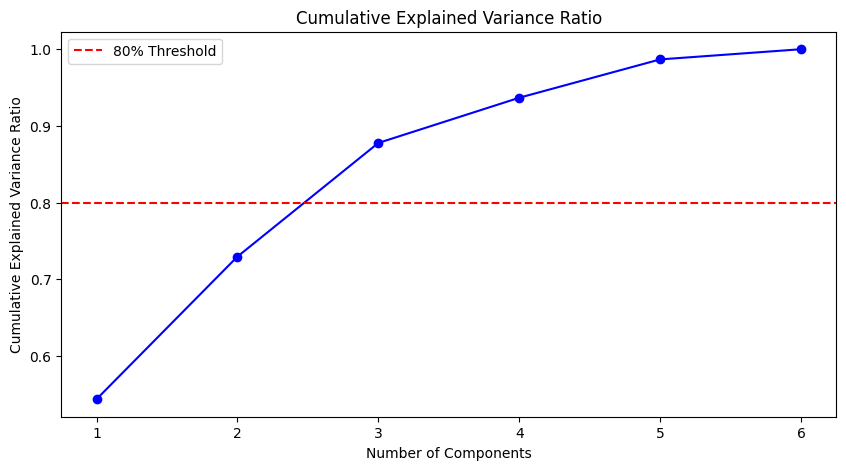

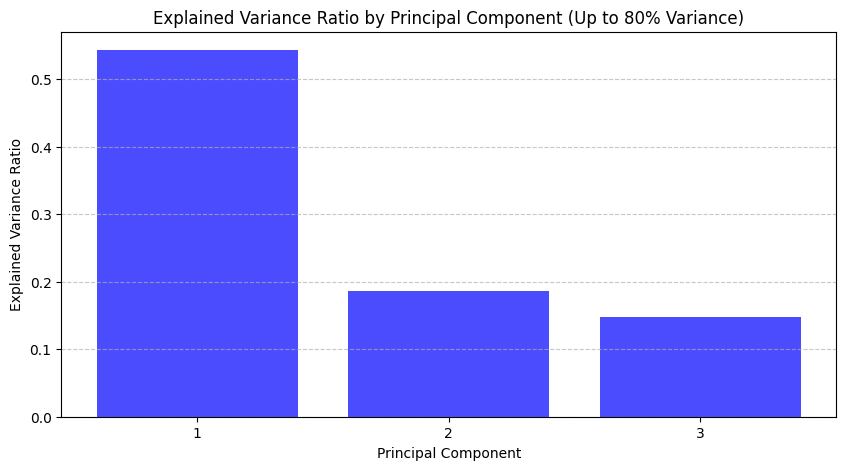

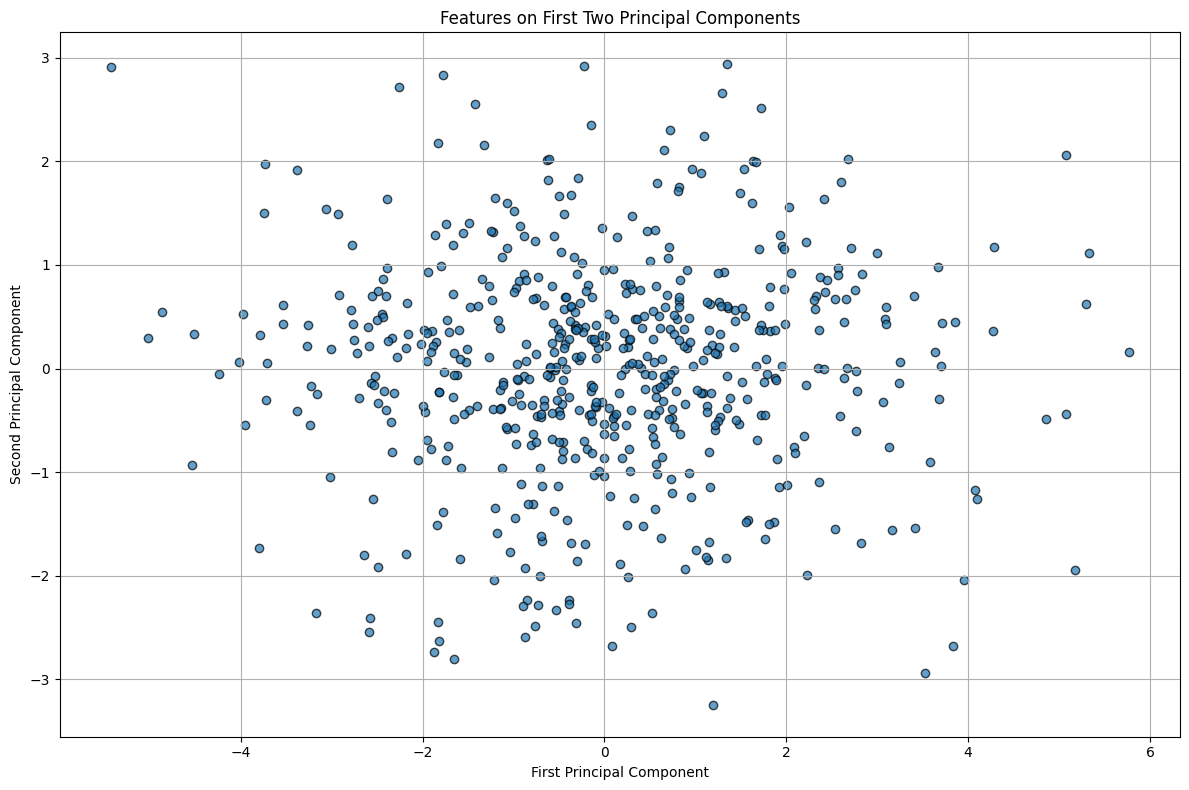

In [19]:
# Plot PCA analysis
plot_cumulative_variance(pca)
plot_explained_variance(pca, n_components)
plot_pca_features(pca, X_pca, n_components)

In [20]:
# Show feature loadings
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
print("\nFeature Loadings:")
print(loadings_df)
print("\nTop Feature Contributions to PC1:")
print(loadings_df.sort_values(by="PC1", ascending=False).head(10))


Feature Loadings:
             PC1       PC2       PC3
r_mean  0.893654 -0.026820 -0.042433
g_mean  0.958354 -0.008800  0.015524
b_mean  0.902548  0.068392  0.036583
w_mean  0.856410 -0.004291 -0.017245
rating  0.020601 -0.738755  0.674886
year   -0.013855  0.752931  0.657428

Top Feature Contributions to PC1:
             PC1       PC2       PC3
g_mean  0.958354 -0.008800  0.015524
b_mean  0.902548  0.068392  0.036583
r_mean  0.893654 -0.026820 -0.042433
w_mean  0.856410 -0.004291 -0.017245
rating  0.020601 -0.738755  0.674886
year   -0.013855  0.752931  0.657428



Step 3: Performing clustering analysis...


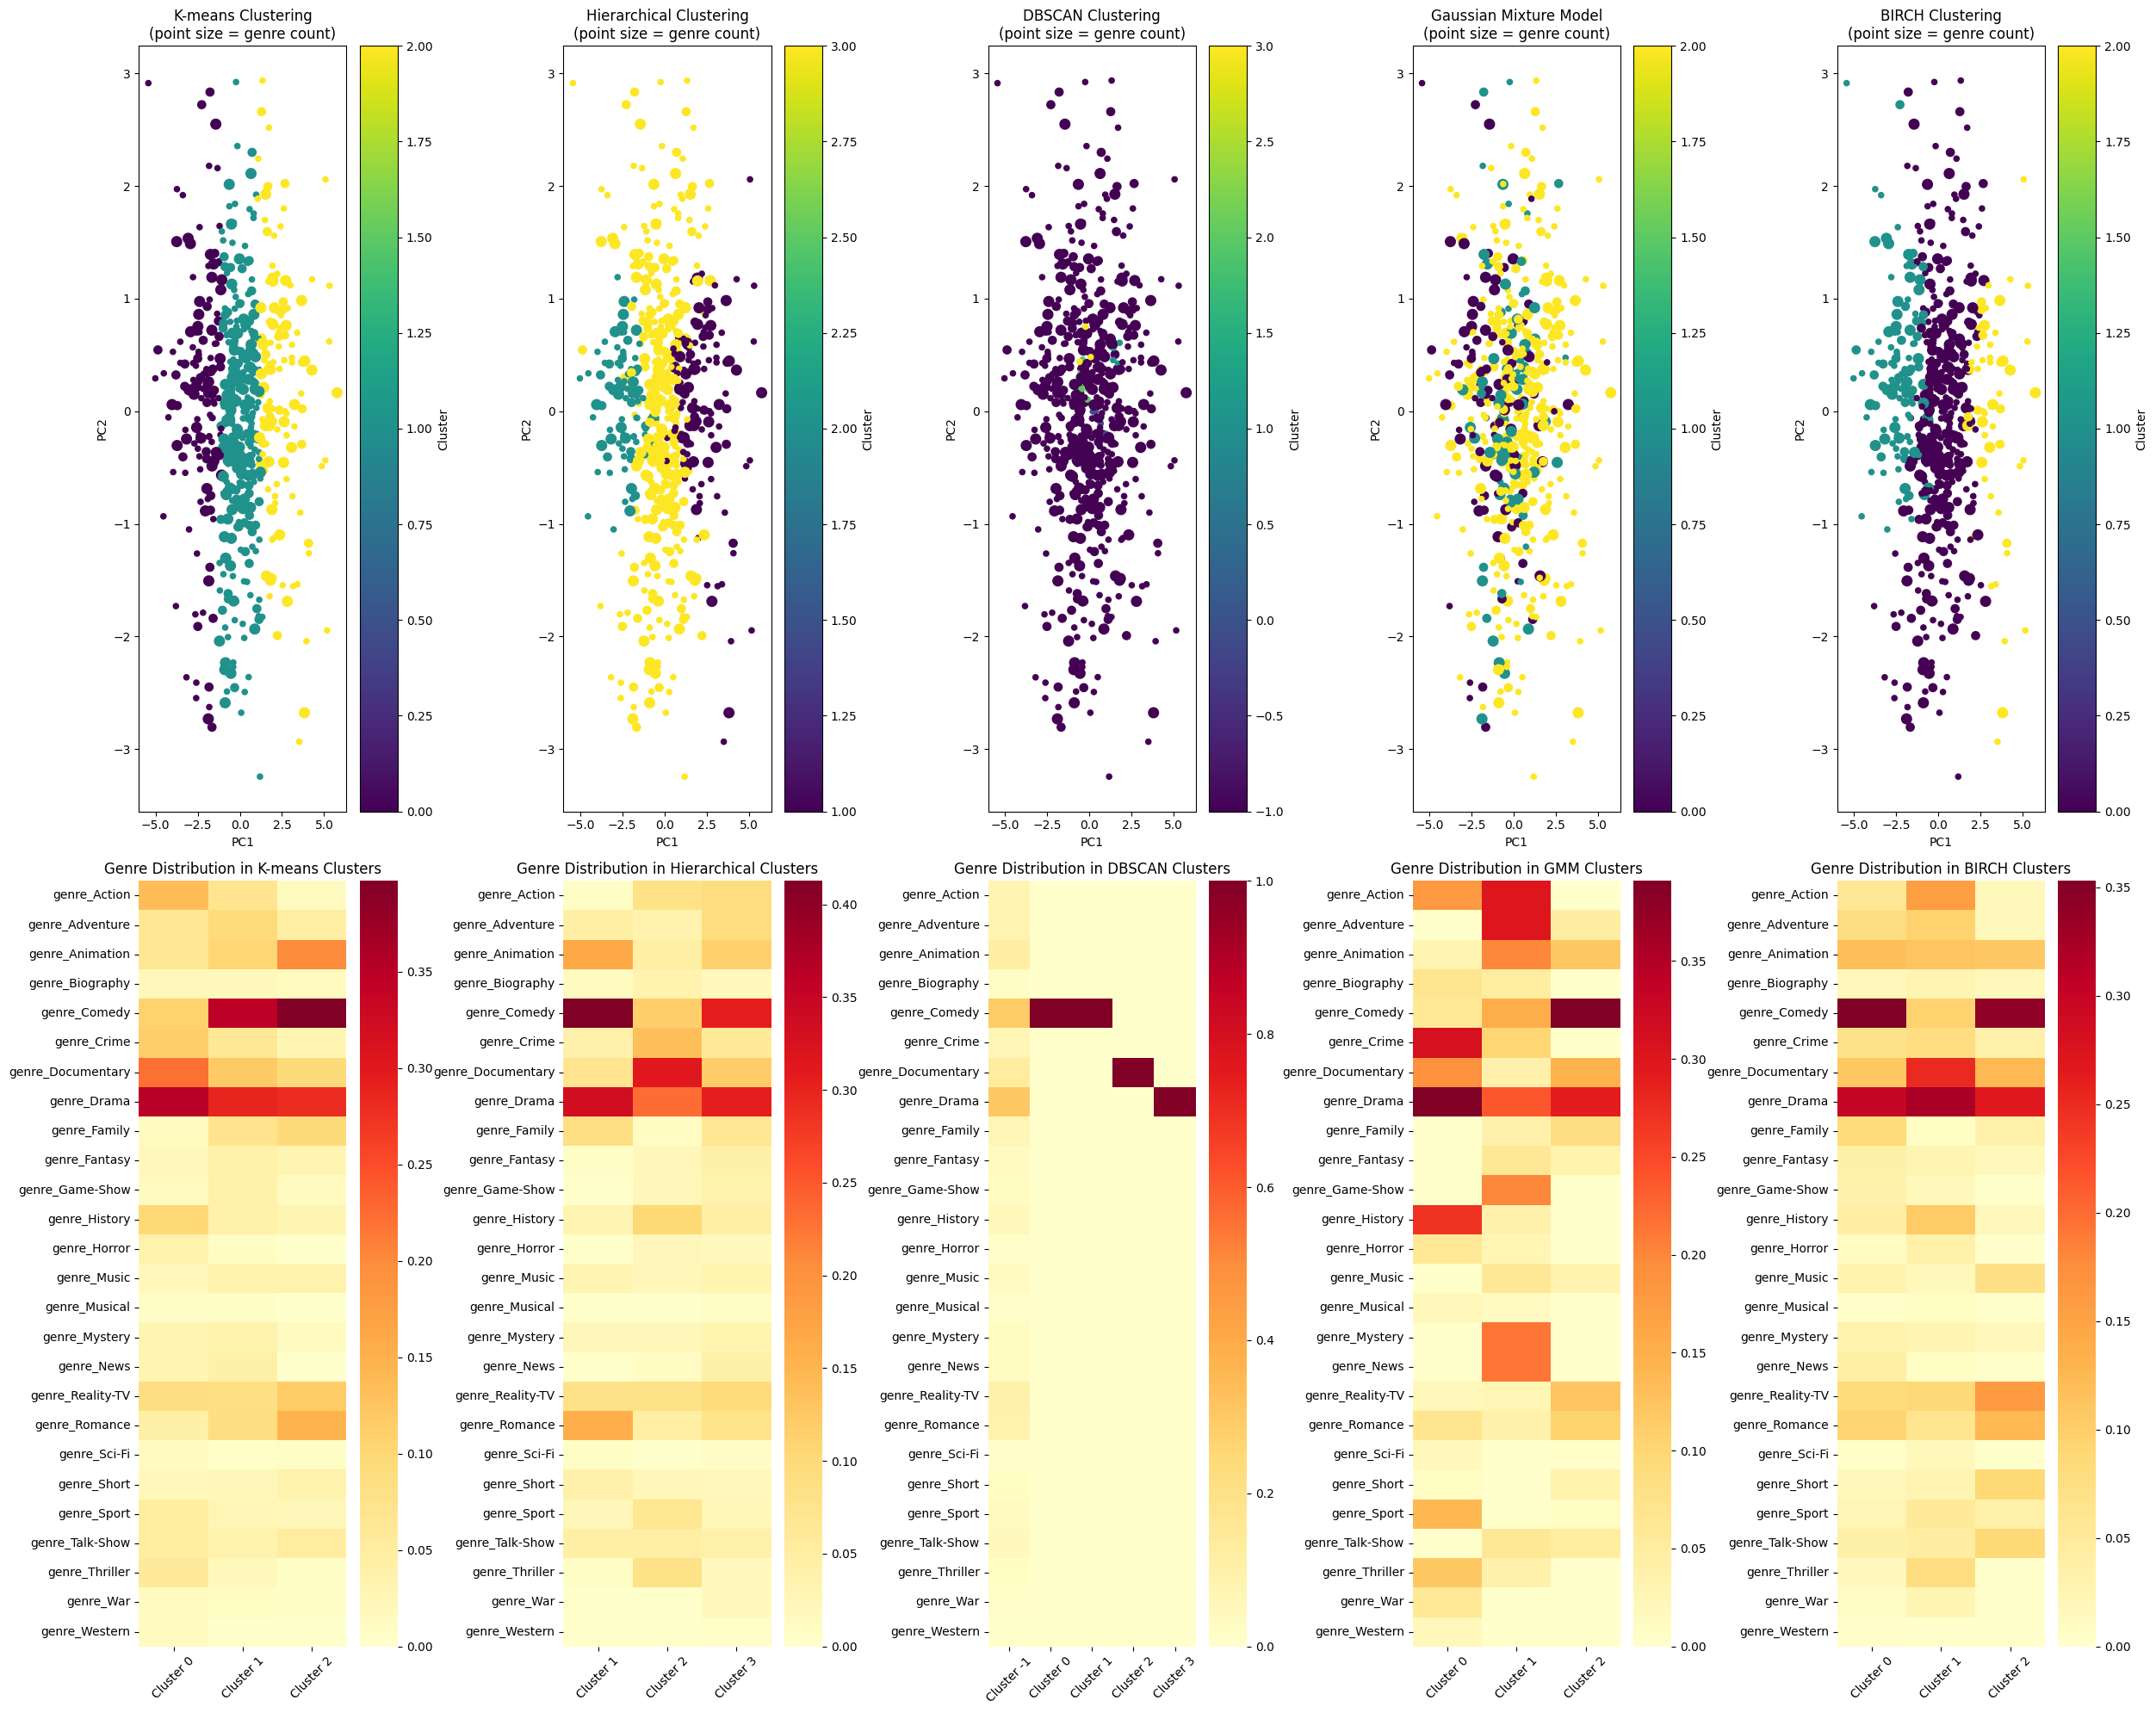

In [21]:
# Perform clustering analysis
print("\nStep 3: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)

In [22]:
# After your PCA analysis
results = analyze_clusters(X_pca)


Clustering Evaluation Results:
      Method  n_clusters  Silhouette Score  Davies-Bouldin Index
     K-means           2             0.240                 1.452
     K-means           3             0.183                 1.631
     K-means           4             0.195                 1.484
     K-means           5             0.208                 1.377
     K-means           6             0.168                 1.532
Hierarchical           2             0.206                 1.401
Hierarchical           3             0.122                 1.572
Hierarchical           4             0.146                 1.633
Hierarchical           5             0.159                 1.574
Hierarchical           6             0.159                 1.475
      DBSCAN           4            -0.314                 1.941
         GMM           2             0.049                 3.574
         GMM           3            -0.003                 4.783
         GMM           4            -0.032                